In [ ]:
"""
Variability of endpoints by phase (Pick / Place / Move).

Question: Do the endpoints of "Place" vary more than those of "Pick" and "Move"
(delivery in the air, without a fixed destination), both between and within subjects?

Design considerations:
  - The comparison is made BY movID. The four "Pick" movements sample positions at
    different shelf locations; combining them would inflate Pick's dispersion simply
    because the targets differ.
  - 3D dispersion = root-mean-square distance to the centroid (RMS, in mm).
  - Exact decomposition: total^2 = within^2 + between^2 (within-subject variance
    plus variance of the subject centroids).
  - Confidence interval for the Place/Pick ratio obtained by bootstrapping SUBJECTS
    (as in the rest of the article).
  - End-of-segment diagnostic: speed at the last sample and duration variability.
    If "Place" ends midway through a movement, some of the variability may result
    from segmentation rather than participant freedom—this analysis does not separate
    these effects.
"""
import os
import sys
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
sys.path.insert(0, '../../..')  # Load Parent directory to import utils
from utils.constants import Configs
 
OUTPUT_DIR = "images"
os.makedirs(OUTPUT_DIR, exist_ok=True)
 
PHASE_ORDER = ["Pick", "Place", "Move"]
PHASE_COLOR = {"Pick": "#1f77b4", "Place": "#d62728", "Move": "#7f7f7f"}

## Functions

In [ ]:
def movement_endpoints(raw_df, n_last=1):
    """
    One row per movement (sub, repID, movID) with initial and final point (x, y, z in mm),
    speed at the last sample, and number of steps. With n_last > 1, uses the median of the last
    n_last samples (robustness to edge effects from the smoothing filter).
    """
    keys = ["sub", "repID", "movID"]
    df = raw_df.sort_values(keys + ["step"])
    grp = df.groupby(keys, sort=False)
    start = grp.head(n_last).groupby(keys)[["x", "y", "z"]].median().add_prefix("start_")
    end = (grp.tail(n_last).groupby(keys)[["x", "y", "z", "vel"]].median()
           .rename(columns={"x": "end_x", "y": "end_y", "z": "end_z", "vel": "end_speed"}))
    n_steps = df.groupby(keys).size().rename("n_steps")
    label = df.groupby(keys)["movLabel"].first()
    return pd.concat([label, start, end, n_steps], axis=1).reset_index()
 
 
def rms3d(pts):
    """Root-mean-square distance to the centroid (mm)."""
    pts = np.asarray(pts, dtype=float)
    return float(np.sqrt(((pts - pts.mean(axis=0)) ** 2).sum(axis=1).mean()))
 
 
def variance_decomposition(pts, subjects):
    """
    Decomposition of variance into components:
    total = within + between (exact identity, 3D variances in mm^2).
    args:
        pts: array (N, 3) with 3D coordinates of N points
        subjects: array (N,) with the subject corresponding to each point
    returns:
        total, within, between: 3D variances (mm^2)
    """
    pts = np.asarray(pts, dtype=float)
    centroid = pts.mean(axis=0)
    sub_centroid = pd.DataFrame(pts).groupby(np.asarray(subjects)).transform("mean").to_numpy()
    total = ((pts - centroid) ** 2).sum(axis=1).mean()
    within = ((pts - sub_centroid) ** 2).sum(axis=1).mean()
    between = ((sub_centroid - centroid) ** 2).sum(axis=1).mean()
    return total, within, between
 
 
def dispersion_table(ep, which="end"):
    """Dispersion of the initial/final point by movID."""
    cols = [f"{which}_x", f"{which}_y", f"{which}_z"]
    rows = []
    for (label, mov), g in ep.groupby(["movLabel", "movID"]):
        total, within, between = variance_decomposition(g[cols].to_numpy(), g["sub"].to_numpy())
        rows.append({
            "phase": label, "movID": mov, "n": len(g),
            "sd_x": g[cols[0]].std(), "sd_y": g[cols[1]].std(), "sd_z": g[cols[2]].std(),
            "range_x": np.ptp(g[cols[0]]), "range_y": np.ptp(g[cols[1]]), "range_z": np.ptp(g[cols[2]]),
            "rms_total": np.sqrt(total), "rms_within": np.sqrt(within), "rms_between": np.sqrt(between),
            "within_share": within / total if total > 0 else np.nan,
            "end_speed_median": g["end_speed"].median(),
            "cv_duration": g["n_steps"].std() / g["n_steps"].mean(),
        })
    tab = pd.DataFrame(rows)
    tab["phase"] = pd.Categorical(tab["phase"], PHASE_ORDER, ordered=True)
    return tab.sort_values(["phase", "movID"]).reset_index(drop=True)
 
 
def phase_summary(tab):
    """Mean by phase of the measures by movID (each movID has equal weight)."""
    return (tab.groupby("phase", observed=True)
            [["sd_x", "sd_y", "sd_z", "range_x", "range_y", "range_z",
              "rms_total", "rms_within", "rms_between", "end_speed_median", "cv_duration"]]
            .mean())
 
 
def bootstrap_dispersion_ratio(ep, num="Place", den="Pick", which="end", n_boot=2000, seed=42,
                               component="total"):
    """
    Ratio between the mean 3D dispersion by movID of two phases, with a subject-bootstrap CI.
    Ratio > 1: the 'num' phase has more dispersed points than the 'den' phase.
    component='total'  -> total dispersion (including between-subject differences)
    component='within' -> only dispersion within each subject (does not depend on
                          positional differences between participants)
    """
    cols = [f"{which}_x", f"{which}_y", f"{which}_z"]
    groups = {}
    for (label, mov, sub), g in ep.groupby(["movLabel", "movID", "sub"]):
        groups.setdefault((label, mov), {})[sub] = g[cols].to_numpy()
    subjects = ep["sub"].unique()
 
    def within_rms3d(arrays):
        sq = sum(((a - a.mean(axis=0)) ** 2).sum() for a in arrays)
        return float(np.sqrt(sq / sum(len(a) for a in arrays)))
 
    def phase_dispersion(label, sampled):
        if component == "within":
            vals = [within_rms3d([d[s] for s in sampled])
                    for (lab, _), d in groups.items() if lab == label]
        else:
            vals = [rms3d(np.vstack([d[s] for s in sampled]))
                    for (lab, _), d in groups.items() if lab == label]
        return float(np.mean(vals))
 
    observed = phase_dispersion(num, subjects) / phase_dispersion(den, subjects)
    rng = np.random.default_rng(seed)
    ratios = []
    for _ in range(n_boot):
        sampled = rng.choice(subjects, size=len(subjects), replace=True)
        ratios.append(phase_dispersion(num, sampled) / phase_dispersion(den, sampled))
    ratios = np.array(ratios)
    return dict(ratio=observed, low=float(np.percentile(ratios, 2.5)),
                high=float(np.percentile(ratios, 97.5)), share_above_1=float((ratios > 1).mean()))
 
 
def plot_endpoints(ep, which="end", save_path=None):
    """Coordinates of the final (or initial) point by movID, colored by phase."""
    movs = sorted(ep["movID"].unique())
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=300, sharex=True)
    rng = np.random.default_rng(0)
    for ax, axis in zip(axes, "xyz"):
        data = [ep.loc[ep.movID == m, f"{which}_{axis}"].to_numpy() for m in movs]
        colors = [PHASE_COLOR[ep.loc[ep.movID == m, "movLabel"].iloc[0]] for m in movs]
        bp = ax.boxplot(data, positions=range(len(movs)), widths=0.6, showfliers=False, patch_artist=True)
        for patch, c in zip(bp["boxes"], colors):
            patch.set_facecolor(c)
            patch.set_alpha(0.35)
        for i, d in enumerate(data):
            ax.scatter(i + rng.uniform(-0.2, 0.2, len(d)), d, s=6, color=colors[i], alpha=0.6)
        ax.set_xticks(range(len(movs)))
        ax.set_xticklabels(movs)
        ax.set_xlabel("movID")
        ax.set_ylabel(f"{which.capitalize()} {axis.upper()} (mm)")
        ax.grid(True, linestyle=":", alpha=0.5)
    handles = [plt.Line2D([0], [0], marker="s", linestyle="", color=PHASE_COLOR[p], alpha=0.5, label=p)
               for p in PHASE_ORDER]
    axes[0].legend(handles=handles, loc="best")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    return fig
 
 
def plot_decomposition_and_speed(ep, tab, save_path=None):
    """Left: between- and within-subject dispersion. Right: speed at the end of the segment."""
    movs = sorted(ep["movID"].unique())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), dpi=300)
    t = tab.set_index("movID").loc[movs]
    x = np.arange(len(movs))
    a1.bar(x - 0.2, t["rms_between"], width=0.4, label="between subjects", color="#4c72b0")
    a1.bar(x + 0.2, t["rms_within"], width=0.4, label="within subjects", color="#dd8452")
    a1.set_xticks(x)
    a1.set_xticklabels(movs)
    a1.set_xlabel("movID")
    a1.set_ylabel("Endpoint dispersion, RMS 3D (mm)")
    a1.legend()
    data = [ep.loc[ep.movID == m, "end_speed"].to_numpy() for m in movs]
    colors = [PHASE_COLOR[ep.loc[ep.movID == m, "movLabel"].iloc[0]] for m in movs]
    bp = a2.boxplot(data, positions=x, widths=0.6, showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.45)
    a2.set_xticks(x)
    a2.set_xticklabels(movs)
    a2.set_xlabel("movID")
    a2.set_ylabel("Speed at last sample (dataset units)")
    for ax in (a1, a2):
        ax.grid(True, linestyle=":", alpha=0.5)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    return fig

## Data

In [3]:
raw_df = pd.read_csv(Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR)
ep = movement_endpoints(raw_df, n_last=1)
print(ep.groupby("movLabel").size())          # esperado: Pick 380, Place 380, Move 95
ep.head()

movLabel
Move      95
Pick     380
Place    380
dtype: int64


,sub,repID,movID,movLabel,start_x,start_y,start_z,end_x,end_y,end_z,end_speed,n_steps
0,1,1,1,Pick,-149.538738,205.584682,897.489098,-357.495870,520.725069,1199.522243,0.004347,111
1,1,1,2,Place,-357.564363,520.695734,1199.423883,-468.257466,132.065277,1123.923805,0.145989,290
2,1,1,3,Pick,-473.091704,142.421760,1125.915304,-341.313152,452.834791,1045.369597,0.022907,185
3,1,1,4,Place,-341.269811,452.791436,1045.365708,-445.566882,178.221814,1072.493339,0.031565,143
4,1,1,5,Pick,-445.604277,178.142767,1072.606579,-404.639867,498.704865,1193.072044,0.017067,160


In [4]:
tab_end = dispersion_table(ep, which="end")
pd.set_option("display.width", 220, "display.max_columns", 30)
print(tab_end.round(2).to_string(index=False))
print("\nMédia por fase (cada movID pesa o mesmo):")
print(phase_summary(tab_end).round(2))
tab_end.to_csv(os.path.join(OUTPUT_DIR, "endpoint_dispersion_by_movID.csv"), index=False)

phase  movID  n  sd_x   sd_y  sd_z  range_x  range_y  range_z  rms_total  rms_within  rms_between  within_share  end_speed_median  cv_duration
 Pick      1 95 73.68  82.36 50.39   352.03   339.46   219.83     120.81       29.25       117.22          0.06              0.03         0.28
 Pick      3 95 70.27  79.28 49.13   318.24   298.83   238.26     116.16       30.25       112.15          0.07              0.02         0.31
 Pick      5 95 73.73  87.57 57.99   325.35   320.24   301.37     127.65       30.96       123.84          0.06              0.03         0.26
 Pick      7 95 73.29  87.85 47.10   376.72   324.71   202.12     123.07       26.87       120.11          0.05              0.03         0.23
Place      2 95 45.40  99.17 70.38   243.53   404.94   284.17     129.11       37.19       123.64          0.08              0.04         0.28
Place      4 95 43.91  98.07 63.33   229.13   381.63   279.16     124.07       35.25       118.95          0.08              0.04         0.20

## Dispertion table Place / Pick and Place / Move (IC Bootstrap per subject)

### Interpretação: variabilidade Place/Pick e Place/Move

O código calcula a razão entre a dispersão dos pontos finais da fase `Place` e das fases `Pick` e `Move`, usando bootstrap por sujeito.

- **Razão > 1:** `Place` apresenta maior dispersão.
- **Razão < 1:** `Place` apresenta menor dispersão.
- **IC95%:** intervalo de confiança obtido pelas reamostragens dos sujeitos.
- **Razão > 1 em (%):** proporção das reamostragens em que `Place` foi mais disperso.

São avaliadas duas componentes:

1. **`total`** — inclui a variabilidade dentro dos sujeitos e as diferenças entre os sujeitos.
2. **`within`** — considera apenas a variabilidade dentro de cada sujeito, removendo diferenças sistemáticas de posição entre participantes.

Se o IC95% não incluir 1, há evidência de diferença entre as fases. Caso inclua 1, a diferença não é conclusiva.

Na análise com as últimas amostras do segmento, a razão `Place/Pick` foi aproximadamente `1,05`, com IC95% `[0,92; 1,17]`. Como o intervalo inclui 1, não há evidência clara de que `Place` seja mais variável que `Pick`. A consistência desse resultado para diferentes valores de `n_last` indica que a conclusão não parece depender apenas da escolha da última amostra.

In [ ]:
for component in ("total", "within"):
    for den in ("Pick", "Move"):
        r = bootstrap_dispersion_ratio(ep, num="Place", den=den, which="end", n_boot=2000, component=component)
        print(f"[{component:6s}] Place / {den:5s}: razão = {r['ratio']:.2f}  IC95% [{r['low']:.2f}, {r['high']:.2f}]  "
              f"(razão > 1 em {100 * r['share_above_1']:.1f}% das reamostragens)")

[total ] Place / Pick : razão = 1.05 mm  IC95% [0.93, 1.19]  (razão > 1 em 77.5% das reamostragens)
[total ] Place / Move : razão = 1.83 mm  IC95% [1.52, 2.23]  (razão > 1 em 100.0% das reamostragens)
[within] Place / Pick : razão = 1.27 mm  IC95% [1.02, 1.66]  (razão > 1 em 98.5% das reamostragens)
[within] Place / Move : razão = 2.30 mm  IC95% [1.95, 2.71]  (razão > 1 em 100.0% das reamostragens)


## n last samples median

In [ ]:
for n_last in (1, 3, 5):
    ep_n = movement_endpoints(raw_df, n_last=n_last)
    r = bootstrap_dispersion_ratio(ep_n, num="Place", den="Pick", which="end", n_boot=500)
    print(f"n_last={n_last}: Place/Pick = {r['ratio']:.2f}  IC95% [{r['low']:.2f}, {r['high']:.2f}]")
# if result is consistent across n_last, it suggests that the endpoint variability is not an artifact of the last sample selection.

n_last=1: Place/Pick = 1.05 mm  IC95% [0.92, 1.17]
n_last=3: Place/Pick = 1.05 mm  IC95% [0.92, 1.17]
n_last=5: Place/Pick = 1.05 mm  IC95% [0.92, 1.17]


## Figures

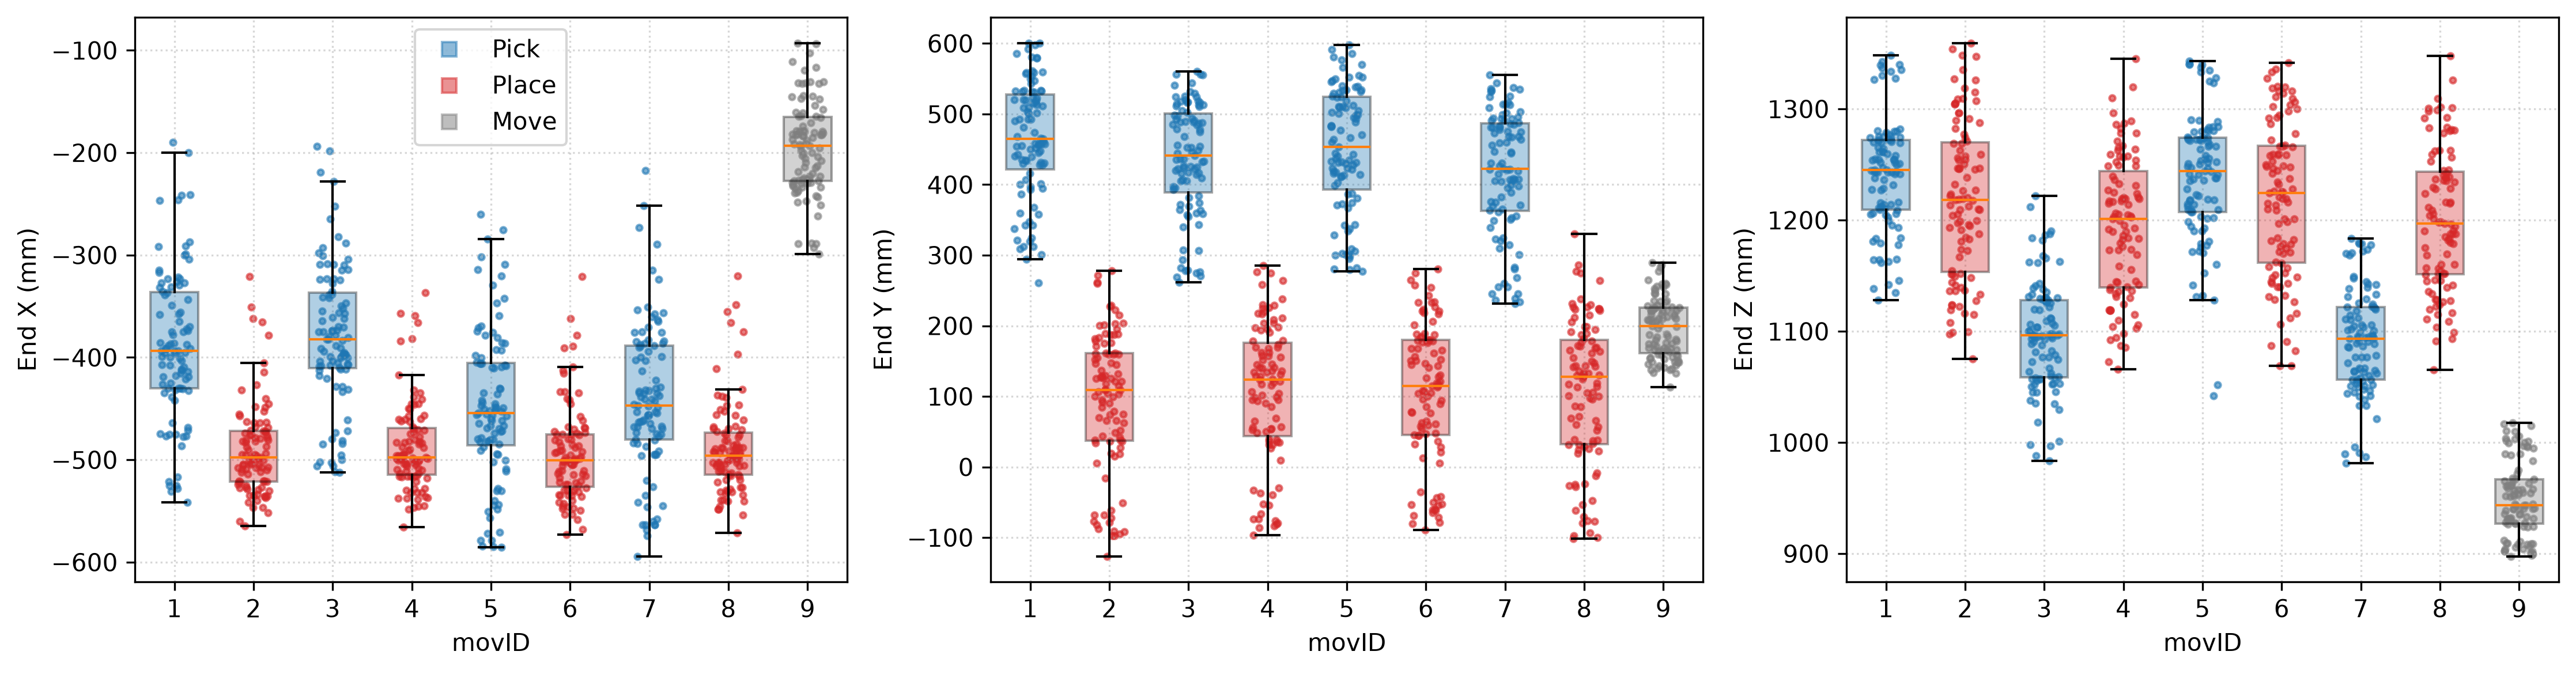

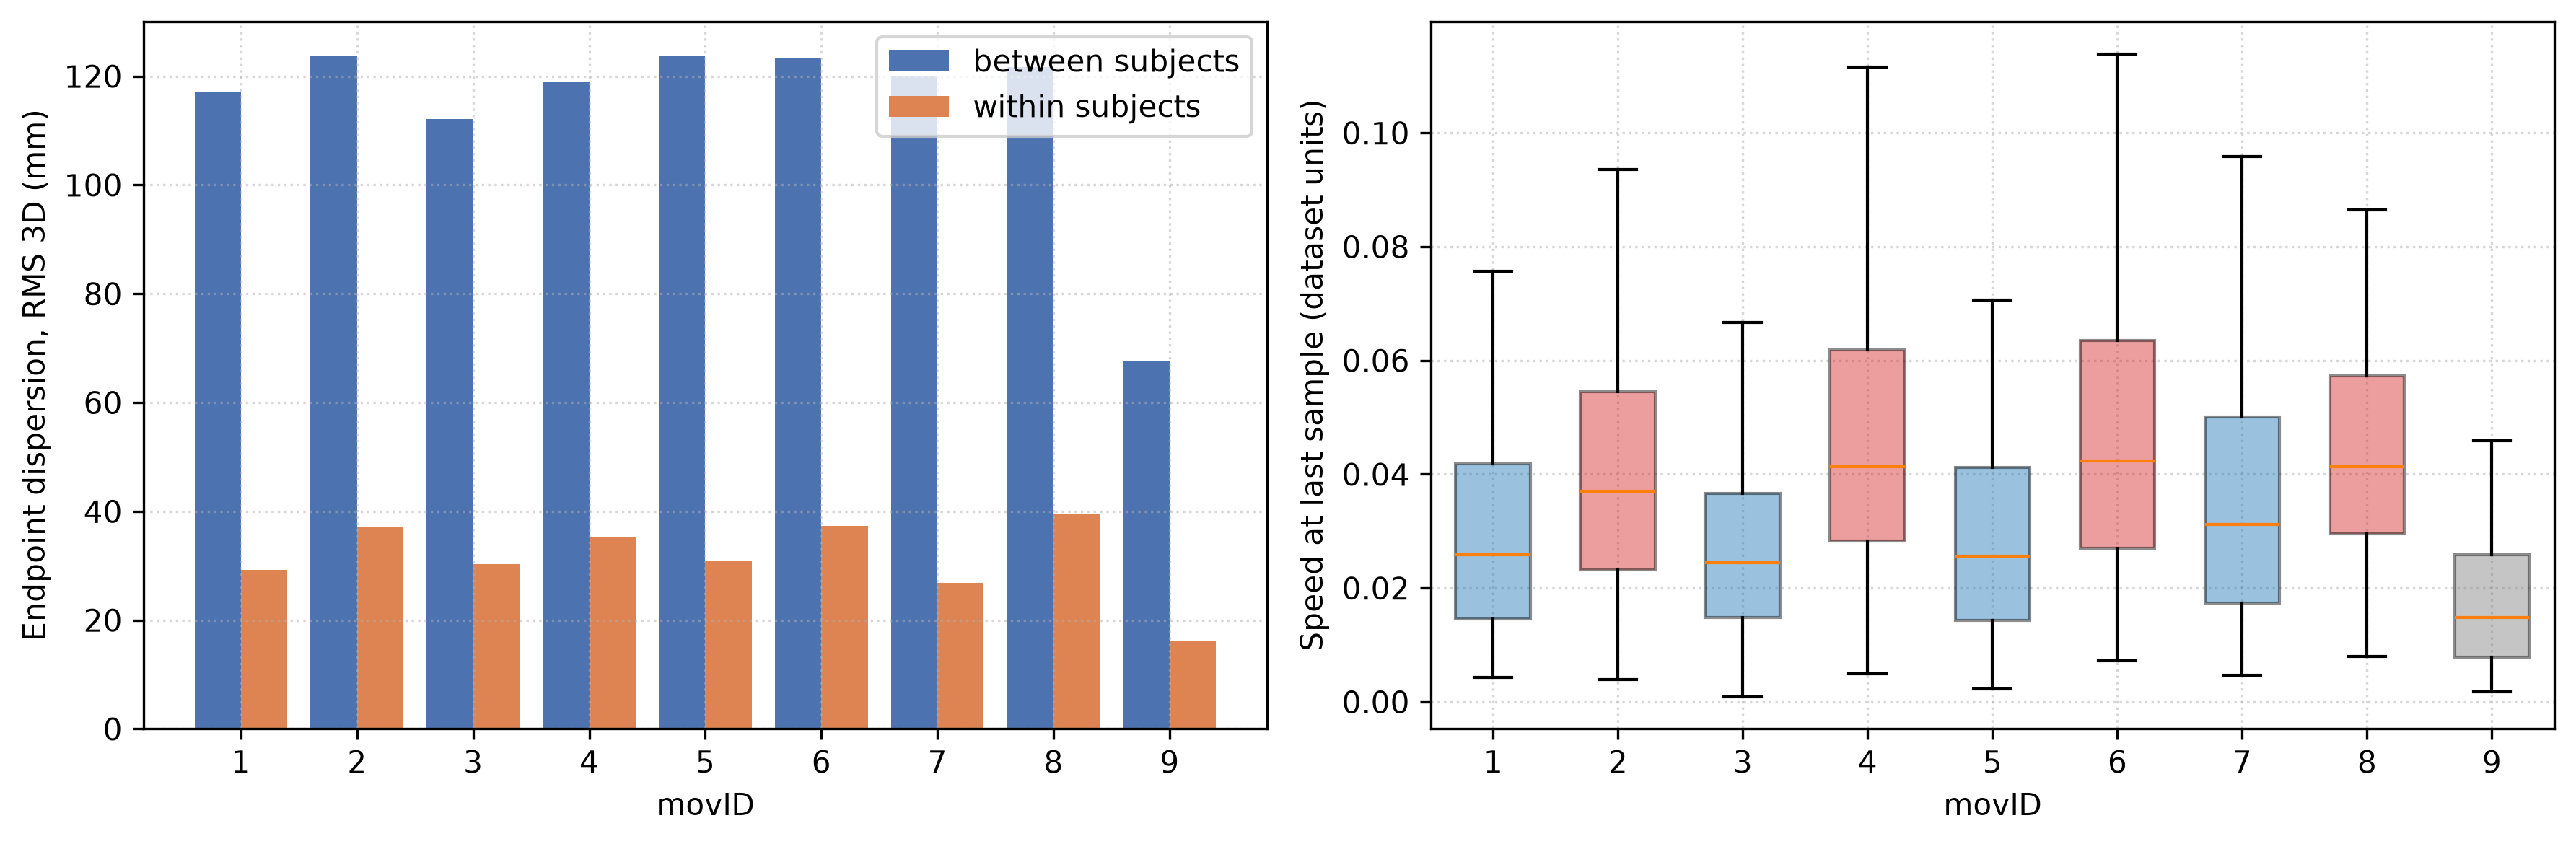

In [7]:
plot_endpoints(ep, which="end", save_path=os.path.join(OUTPUT_DIR, "endpoint_variability.png"))
plot_decomposition_and_speed(ep, tab_end, save_path=os.path.join(OUTPUT_DIR, "endpoint_decomposition_speed.png"))
plt.show()